# ĐỀ TÀI 1: TỐI ƯU HÓA DANH MỤC ĐẦU TƯ VN30 BẰNG MÔ HÌNH MARKOWITZ VÀ KIỂM THỬ OUT-OF-SAMPLE (BACKTESTING)

**Cấu trúc notebook**

- **Chương 1:** Thu thập & chuẩn hóa dữ liệu (giá điều chỉnh, lợi nhuận logarit, Mean/Covariance thường niên hóa 252 ngày)
- **Chương 2:** Mô hình Markowitz (In-sample): MVP, Tangency (Max Sharpe), Monte Carlo 10,000 danh mục, Efficient Frontier, CML
- **Chương 3:** Ràng buộc w_i ≤ 25% & kiểm thử Out-of-sample: Markowitz vs 1/N vs VN-Index (kèm rolling backtest mở rộng)

*Chạy: bấm **Run All**. Dữ liệu được đọc từ `data/raw_prices.csv` nếu đã có (nhanh), nếu chưa có sẽ tải từ internet (chậm hơn).*

In [ ]:
# Hiển thị biểu đồ ngay trong notebook
%matplotlib inline

In [20]:
# %% ============================ 0. CẤU HÌNH ============================
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 6), "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

# ---- Danh sách cổ phiếu (10 mã thuộc nhóm VN30, đa ngành) ----
TICKERS = ["VCB", "ACB", "TCB", "FPT", "HPG", "VNM", "MWG", "GAS", "SSI", "VHM"]
BENCHMARK = "VNINDEX"

# ---- Khung thời gian ----
# In-sample (ước lượng): 4 năm | Out-of-sample (kiểm thử): 12 tháng kế tiếp
DATA_START = "2021-11-01"
TRAIN_END = "2025-10-31"      # kết thúc giai đoạn In-sample
TEST_START = "2025-11-01"     # bắt đầu giai đoạn Out-of-sample
DATA_END = "2026-10-31"

# ---- Tham số mô hình ----
TRADING_DAYS = 252            # số ngày giao dịch/năm (theo đề cương)
RF = 0.03                     # lãi suất phi rủi ro/năm (3%) - có thể chỉnh (VD: lãi suất TPCP 10 năm)
N_SIM = 10_000                # số danh mục ngẫu nhiên Monte Carlo
MAX_WEIGHT = 0.25             # ràng buộc tỷ trọng tối đa (Chương 3)
SEED = 42

# ---- Nguồn dữ liệu ----
# "auto"      : dùng file CSV nếu đã có, nếu chưa thì tải từ vnstock -> yfinance
# "csv"       : chỉ đọc từ data/raw_prices.csv (bạn tự chuẩn bị)
# "synthetic" : dữ liệu GIẢ LẬP để chạy thử code (KHÔNG dùng để nộp bài)
DATA_SOURCE = "auto"

DATA_DIR, OUT_DIR = "data", "outputs"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)

Đọc dữ liệu có sẵn từ data/raw_prices.csv

Tỷ lệ dữ liệu thiếu (%):
 VCB    0.69
ACB    0.00
TCB    0.00
FPT    0.00
HPG    0.00
VNM    0.69
MWG    0.69
GAS    0.00
SSI    0.00
VHM    0.00

Dữ liệu sạch: 1305 phiên x 10 mã, từ 2021-11-01 đến 2026-10-30
In-sample    : 2021-11-02 → 2025-10-31 (1044 phiên)
Out-of-sample: 2025-11-03 → 2026-10-30 (260 phiên)

=== THỐNG KÊ TỪNG CỔ PHIẾU (In-sample) ===
     Lợi nhuận kỳ vọng (năm)  Độ lệch chuẩn (năm)  Sharpe riêng lẻ
VCB                  -0.0128               0.3060          -0.1398
ACB                   0.1209               0.2861           0.3177
TCB                   0.0921               0.3203           0.1939
FPT                   0.1764               0.2694           0.5434
HPG                  -0.0462               0.3322          -0.2294
VNM                  -0.0528               0.2240          -0.3697
MWG                   0.0683               0.3468           0.1103
GAS                  -0.0804               0.2822          -0.39

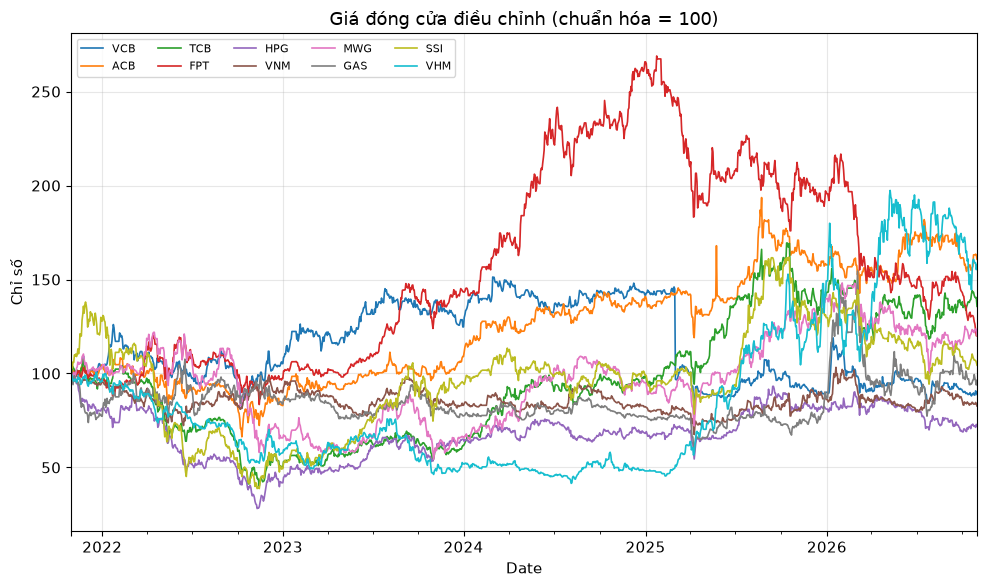

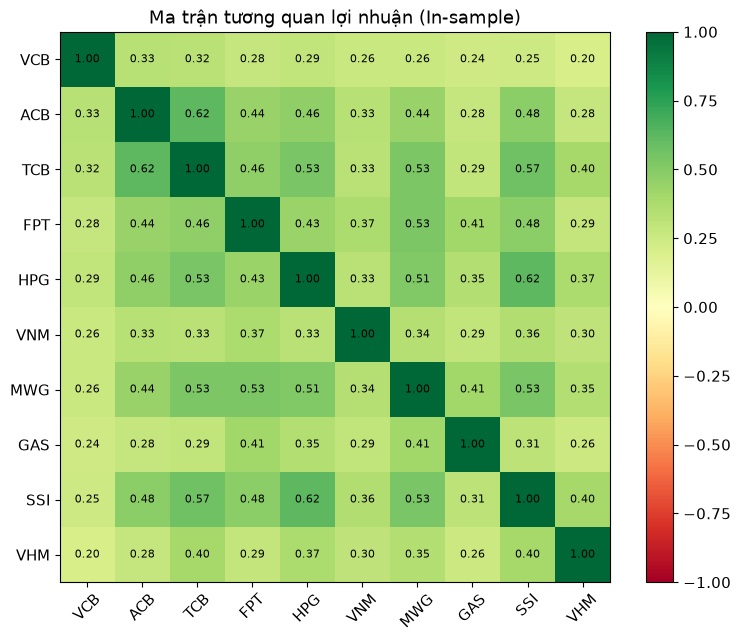

In [14]:
# %% ============ CHƯƠNG 1: THU THẬP & CHUẨN HÓA DỮ LIỆU ============
# ---------- 1.1 Các hàm tải dữ liệu ----------
def fetch_vnstock(symbol, start, end, retries=3):
    """Tải giá đóng cửa từ thư viện vnstock (nguồn VCI)."""
    try:
        from vnstock import Vnstock
    except ImportError:
        return None          # chưa cài vnstock -> chuyển sang yfinance
    for k in range(retries):
        try:
            df = Vnstock().stock(symbol=symbol, source="VCI").quote.history(
                start=start, end=end, interval="1D")
            s = df.set_index(pd.to_datetime(df["time"]))["close"].astype(float)
            s.name = symbol
            return s
        except Exception as e:
            print(f"   [vnstock] {symbol} lỗi lần {k+1}: {e}")
            time.sleep(5)   # tránh bị giới hạn số request
    return None


def fetch_yfinance(symbol, start, end):
    """Tải giá đã điều chỉnh từ Yahoo Finance (mã VN có hậu tố .VN)."""
    try:
        import yfinance as yf
    except ImportError:
        print("   [yfinance] chưa cài: chạy  python3 -m pip install yfinance")
        return None
    ticker = "^VNINDEX" if symbol == "VNINDEX" else f"{symbol}.VN"
    try:
        df = yf.Ticker(ticker).history(start=start, end=end, auto_adjust=True)
        if df.empty:
            return None
        s = df["Close"].astype(float)
        s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
        s.name = symbol
        return s
    except Exception as e:
        print(f"   [yfinance] {symbol} lỗi: {e}")
        return None


def make_synthetic_prices(symbols, start, end):
    """Sinh giá giả lập (mô hình 1 nhân tố thị trường) - CHỈ để test code."""
    dates = pd.bdate_range(start, end)
    n = len(symbols)
    rng = np.random.default_rng(SEED)
    mu = rng.uniform(0.00, 0.30, n) / TRADING_DAYS            # lợi nhuận kỳ vọng/ngày
    beta = rng.uniform(0.6, 1.3, n)
    mkt = rng.normal(0.0, 0.17 / np.sqrt(TRADING_DAYS), len(dates))      # nhân tố thị trường
    idio = rng.normal(0.0, 1.0, (len(dates), n)) * rng.uniform(0.15, 0.30, n) / np.sqrt(TRADING_DAYS)
    rets = mu + np.outer(mkt, beta) + idio
    df = pd.DataFrame(20 * np.exp(np.cumsum(rets, axis=0)), index=dates, columns=symbols)
    df[BENCHMARK] = 1000 * np.exp(np.cumsum(mkt + 0.08 / TRADING_DAYS))
    return df


def load_all_prices():
    raw_path = os.path.join(DATA_DIR, "raw_prices.csv")

    if DATA_SOURCE == "synthetic":
        print("⚠️  Đang dùng dữ liệu GIẢ LẬP - chỉ để chạy thử!")
        return make_synthetic_prices(TICKERS, DATA_START, DATA_END)

    if os.path.exists(raw_path):
        print(f"Đọc dữ liệu có sẵn từ {raw_path}")
        return pd.read_csv(raw_path, index_col=0, parse_dates=True)

    if DATA_SOURCE == "csv":
        raise FileNotFoundError(f"Không thấy {raw_path}. Hãy đặt file giá (cột = mã CP, index = ngày) vào đó.")

    print("Đang tải dữ liệu từ internet...")
    series = []
    for sym in TICKERS + [BENCHMARK]:
        s = fetch_vnstock(sym, DATA_START, DATA_END)
        if s is None or s.empty:
            s = fetch_yfinance(sym, DATA_START, DATA_END)
        if s is None or s.empty:
            print(f"   ❌ Không tải được {sym}")
            continue
        print(f"   ✅ {sym}: {len(s)} phiên")
        series.append(s)
        time.sleep(1)
    if not series:
        raise RuntimeError("Không tải được dữ liệu nào. Cài yfinance/vnstock, kiểm tra mạng, "
                           "hoặc tự đặt file giá vào data/raw_prices.csv rồi dùng DATA_SOURCE='csv'.")
    df = pd.concat(series, axis=1)
    df.to_csv(raw_path)      # lưu file dữ liệu thô (sản phẩm nộp #3)
    return df


# ---------- 1.2 Chuẩn hóa dữ liệu ----------
raw = load_all_prices().sort_index()
raw = raw.loc[DATA_START:DATA_END]

# Tách chỉ số VN-Index riêng (nếu tải được)
vnindex = raw[BENCHMARK].dropna() if BENCHMARK in raw.columns else None
prices = raw[[c for c in TICKERS if c in raw.columns]].copy()
TICKERS = list(prices.columns)           # cập nhật nếu có mã không tải được
N = len(TICKERS)

# Làm sạch: loại cột thiếu quá nhiều, điền ô trống nhỏ bằng giá liền trước
missing_pct = prices.isna().mean()
print("\nTỷ lệ dữ liệu thiếu (%):\n", (missing_pct * 100).round(2).to_string())
prices = prices.loc[:, missing_pct < 0.10].ffill().dropna()
TICKERS = list(prices.columns)
N = len(TICKERS)
assert N >= 4, "Cần ≥ 4 mã để ràng buộc w_i <= 25% khả thi (4 x 25% = 100%)."

print(f"\nDữ liệu sạch: {prices.shape[0]} phiên x {N} mã, từ {prices.index[0].date()} đến {prices.index[-1].date()}")

# ---------- 1.3 Lợi nhuận logarit & thường niên hóa ----------
log_ret = np.log(prices / prices.shift(1)).dropna()

# Chia In-sample / Out-of-sample
ret_train = log_ret.loc[:TRAIN_END]
ret_test = log_ret.loc[TEST_START:]
print(f"In-sample    : {ret_train.index[0].date()} → {ret_train.index[-1].date()} ({len(ret_train)} phiên)")
print(f"Out-of-sample: {ret_test.index[0].date()} → {ret_test.index[-1].date()} ({len(ret_test)} phiên)")


def annual_stats(returns):
    """Trả về vector lợi nhuận kỳ vọng và ma trận hiệp phương sai (thường niên hóa)."""
    mean_a = returns.mean() * TRADING_DAYS
    cov_a = returns.cov() * TRADING_DAYS
    return mean_a, cov_a


mu, cov = annual_stats(ret_train)          # ước lượng trên In-sample

summary = pd.DataFrame({
    "Lợi nhuận kỳ vọng (năm)": mu,
    "Độ lệch chuẩn (năm)": np.sqrt(np.diag(cov)),
})
summary["Sharpe riêng lẻ"] = (summary.iloc[:, 0] - RF) / summary.iloc[:, 1]
print("\n=== THỐNG KÊ TỪNG CỔ PHIẾU (In-sample) ===")
print(summary.round(4).to_string())
print("\n=== MA TRẬN HIỆP PHƯƠNG SAI (Covariance, thường niên) ===")
print(cov.round(4).to_string())

# Lưu dữ liệu đã xử lý (sản phẩm nộp #3)
prices.to_csv(os.path.join(DATA_DIR, "clean_prices.csv"))
log_ret.to_csv(os.path.join(DATA_DIR, "log_returns.csv"))
with pd.ExcelWriter(os.path.join(DATA_DIR, "processed_data.xlsx")) as xw:
    prices.to_excel(xw, sheet_name="Prices")
    log_ret.to_excel(xw, sheet_name="LogReturns")
    summary.to_excel(xw, sheet_name="Stats")
    cov.to_excel(xw, sheet_name="Covariance")
    ret_train.corr().to_excel(xw, sheet_name="Correlation")

# Biểu đồ: giá chuẩn hóa & heatmap tương quan
fig, ax = plt.subplots()
(prices / prices.iloc[0] * 100).plot(ax=ax, lw=1.2)
ax.set_title("Giá đóng cửa điều chỉnh (chuẩn hóa = 100)")
ax.set_ylabel("Chỉ số")
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "01_gia_chuan_hoa.png"), dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 6.5))
corr = ret_train.corr()
im = ax.imshow(corr, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(N)); ax.set_xticklabels(TICKERS, rotation=45)
ax.set_yticks(range(N)); ax.set_yticklabels(TICKERS)
for i in range(N):
    for j in range(N):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
plt.colorbar(im)
ax.set_title("Ma trận tương quan lợi nhuận (In-sample)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "02_heatmap_tuong_quan.png"), dpi=150)
plt.show()


=== KẾT QUẢ IN-SAMPLE (chỉ Long-only) ===
                       Lợi nhuận (năm)  Độ biến động (năm)  Sharpe
Danh mục                                                          
MVP                             0.0036              0.1771 -0.1488
Tangency (Max Sharpe)           0.1680              0.2509  0.5500

Tỷ trọng:
        MVP  Tangency
VCB  14.35      0.00
ACB  11.21     15.12
TCB   0.00      0.00
FPT  11.34     84.88
HPG   0.00      0.00
VNM  37.20      0.00
MWG   0.00      0.00
GAS  16.69      0.00
SSI   0.00      0.00
VHM   9.22      0.00


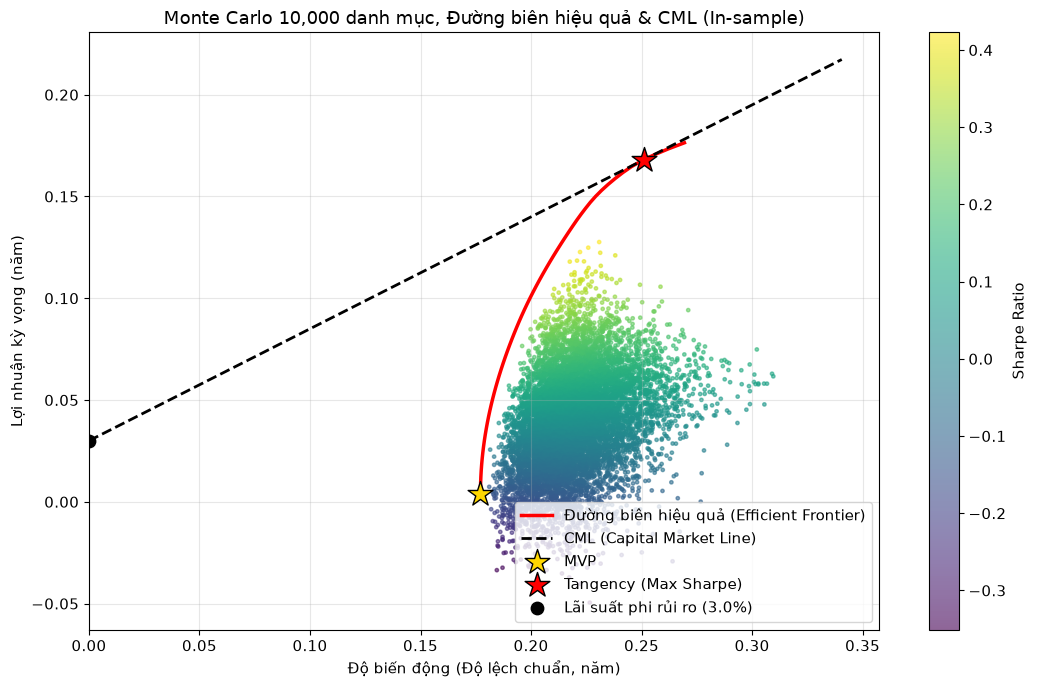

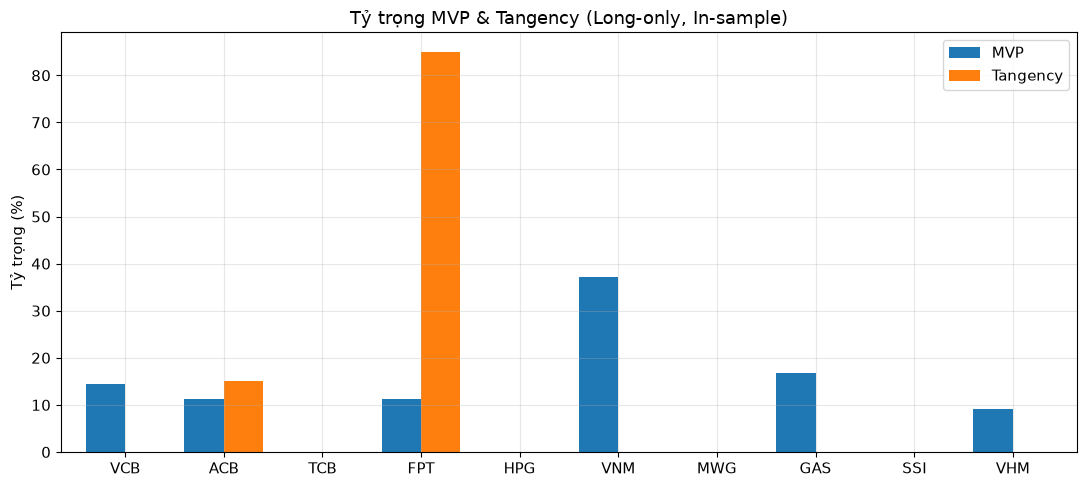

In [15]:
# %% ========= CHƯƠNG 2: MÔ HÌNH TỐI ƯU HÓA MARKOWITZ (IN-SAMPLE) =========
# ---------- 2.1 Các hàm cơ bản ----------
def port_return(w, mu):
    return float(w @ mu)


def port_vol(w, cov):
    return float(np.sqrt(w @ cov @ w))


def port_sharpe(w, mu, cov, rf=RF):
    return (port_return(w, mu) - rf) / port_vol(w, cov)


def optimize_mvp(mu, cov, max_w=1.0):
    """Minimum Variance Portfolio: min w'Σw  s.t. Σw=1, 0<=w<=max_w."""
    n = len(mu)
    res = minimize(lambda w: w @ cov.values @ w, x0=np.ones(n) / n, method="SLSQP",
                   bounds=[(0, max_w)] * n,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
                   options={"ftol": 1e-12, "maxiter": 1000})
    return res.x


def optimize_tangency(mu, cov, rf=RF, max_w=1.0):
    """Tangency Portfolio: max Sharpe  s.t. Σw=1, 0<=w<=max_w."""
    n = len(mu)
    best = None
    # Thử nhiều điểm xuất phát để tránh cực trị địa phương
    starts = [np.ones(n) / n] + [np.random.dirichlet(np.ones(n)) for _ in range(10)]
    for x0 in starts:
        x0 = np.minimum(x0, max_w); x0 = x0 / x0.sum()
        res = minimize(lambda w: -port_sharpe(w, mu.values, cov.values, rf), x0=x0, method="SLSQP",
                       bounds=[(0, max_w)] * n,
                       constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
                       options={"ftol": 1e-12, "maxiter": 1000})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    return best.x


def efficient_frontier(mu, cov, n_points=60, max_w=1.0):
    """Đường biên hiệu quả: với mỗi mức lợi nhuận mục tiêu, tìm danh mục có độ biến động nhỏ nhất."""
    n = len(mu)
    w_mvp = optimize_mvp(mu, cov, max_w)
    r_min = port_return(w_mvp, mu.values)
    # Lợi nhuận tối đa khả thi dưới ràng buộc
    from scipy.optimize import linprog
    lp = linprog(-mu.values, A_eq=[np.ones(n)], b_eq=[1], bounds=[(0, max_w)] * n)
    r_max = -lp.fun
    targets = np.linspace(r_min, r_max, n_points)
    vols, rets, x0 = [], [], w_mvp
    for t in targets:
        res = minimize(lambda w: w @ cov.values @ w, x0=x0, method="SLSQP",
                       bounds=[(0, max_w)] * n,
                       constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                    {"type": "eq", "fun": lambda w, t=t: w @ mu.values - t}],
                       options={"ftol": 1e-12, "maxiter": 1000})
        if res.success:
            vols.append(port_vol(res.x, cov.values)); rets.append(t); x0 = res.x
    return np.array(vols), np.array(rets)


def monte_carlo(mu, cov, n_sim=N_SIM, rf=RF):
    """Mô phỏng n_sim danh mục ngẫu nhiên long-only (phân phối Dirichlet)."""
    W = np.random.dirichlet(np.ones(len(mu)), size=n_sim)
    R = W @ mu.values
    V = np.sqrt(np.einsum("ij,jk,ik->i", W, cov.values, W))
    return W, R, V, (R - rf) / V


# ---------- 2.2 Chạy tối ưu hóa (chỉ ràng buộc Long-only) ----------
w_mvp = optimize_mvp(mu, cov)
w_tan = optimize_tangency(mu, cov)


def describe(name, w):
    return {"Danh mục": name,
            "Lợi nhuận (năm)": port_return(w, mu.values),
            "Độ biến động (năm)": port_vol(w, cov.values),
            "Sharpe": port_sharpe(w, mu.values, cov.values)}


tab2 = pd.DataFrame([describe("MVP", w_mvp), describe("Tangency (Max Sharpe)", w_tan)]).set_index("Danh mục")
weights2 = pd.DataFrame({"MVP": w_mvp, "Tangency": w_tan}, index=TICKERS)
print("\n=== KẾT QUẢ IN-SAMPLE (chỉ Long-only) ===")
print(tab2.round(4).to_string())
print("\nTỷ trọng:\n", (weights2 * 100).round(2).to_string())

# ---------- 2.3 Monte Carlo + Efficient Frontier + CML ----------
W_sim, R_sim, V_sim, S_sim = monte_carlo(mu, cov)
ef_vol, ef_ret = efficient_frontier(mu, cov)

fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(V_sim, R_sim, c=S_sim, cmap="viridis", s=6, alpha=0.6)
plt.colorbar(sc, label="Sharpe Ratio")
ax.plot(ef_vol, ef_ret, "r-", lw=2.5, label="Đường biên hiệu quả (Efficient Frontier)")

# Đường CML: đi từ (0, rf) qua điểm Tangency
vol_t, ret_t = port_vol(w_tan, cov.values), port_return(w_tan, mu.values)
x_cml = np.linspace(0, max(V_sim.max(), vol_t) * 1.1, 100)
slope = (ret_t - RF) / vol_t
ax.plot(x_cml, RF + slope * x_cml, "k--", lw=2, label="CML (Capital Market Line)")

ax.scatter(port_vol(w_mvp, cov.values), port_return(w_mvp, mu.values), marker="*", s=350, c="gold",
           edgecolors="k", zorder=5, label="MVP")
ax.scatter(vol_t, ret_t, marker="*", s=350, c="red", edgecolors="k", zorder=5, label="Tangency (Max Sharpe)")
ax.scatter(0, RF, marker="o", s=80, c="black", zorder=5, label=f"Lãi suất phi rủi ro ({RF:.1%})")
ax.set_xlabel("Độ biến động (Độ lệch chuẩn, năm)")
ax.set_ylabel("Lợi nhuận kỳ vọng (năm)")
ax.set_title(f"Monte Carlo {N_SIM:,} danh mục, Đường biên hiệu quả & CML (In-sample)")
ax.set_xlim(left=0)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "03_efficient_frontier_CML.png"), dpi=150)
plt.show()

# Biểu đồ tỷ trọng
ax = (weights2 * 100).plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_ylabel("Tỷ trọng (%)"); ax.set_title("Tỷ trọng MVP & Tangency (Long-only, In-sample)")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "04_ty_trong_long_only.png"), dpi=150)
plt.show()


=== TỶ TRỌNG KHI CÓ RÀNG BUỘC w_i <= 25% ===
     MVP (cap 25%)  Tangency (cap 25%)   1/N
VCB          16.45                 0.0  10.0
ACB          13.55                25.0  10.0
TCB           0.00                25.0  10.0
FPT          14.42                25.0  10.0
HPG           0.10                 0.0  10.0
VNM          25.00                 0.0  10.0
MWG           0.00                 7.9  10.0
GAS          19.08                 0.0  10.0
SSI           0.00                 0.0  10.0
VHM          11.41                17.1  10.0


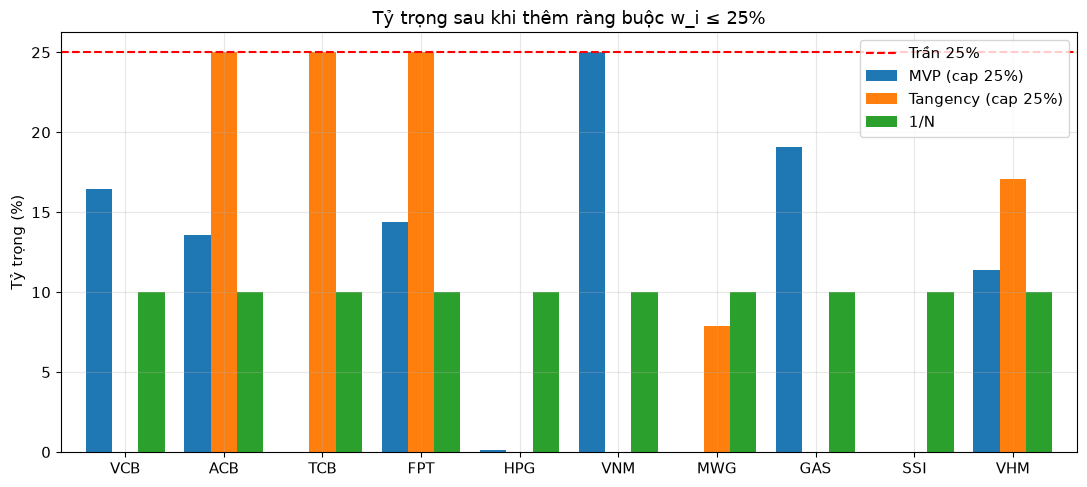

⚠️  Không có dữ liệu VN-Index → bỏ qua benchmark. Bạn có thể tự thêm cột 'VNINDEX' vào data/raw_prices.csv.

=== KẾT QUẢ OUT-OF-SAMPLE (2025-11-03 → 2026-10-30) ===
                                  Lợi nhuận tích lũy  Lợi nhuận/năm  Độ biến động/năm  Sharpe  Max Drawdown
Markowitz - Tangency (cap 25%)               -0.0938        -0.0910            0.2323 -0.5209       -0.2170
Markowitz - MVP (cap 25%)                     0.0446         0.0432            0.1930  0.0684       -0.1931
Markowitz - Tangency (không cap)             -0.3708        -0.3618            0.2742 -1.4291       -0.3925
Đều trọng số 1/N                             -0.0240        -0.0232            0.1964 -0.2711       -0.1984

=== SAI SỐ ƯỚC LƯỢNG (Estimation Error): Sharpe In-sample vs Out-of-sample ===
                                  Sharpe In-sample  Sharpe Out-of-sample  Chênh lệch
Markowitz - Tangency (cap 25%)              0.4939               -0.5209     -1.0149
Markowitz - MVP (cap 25%)                   0

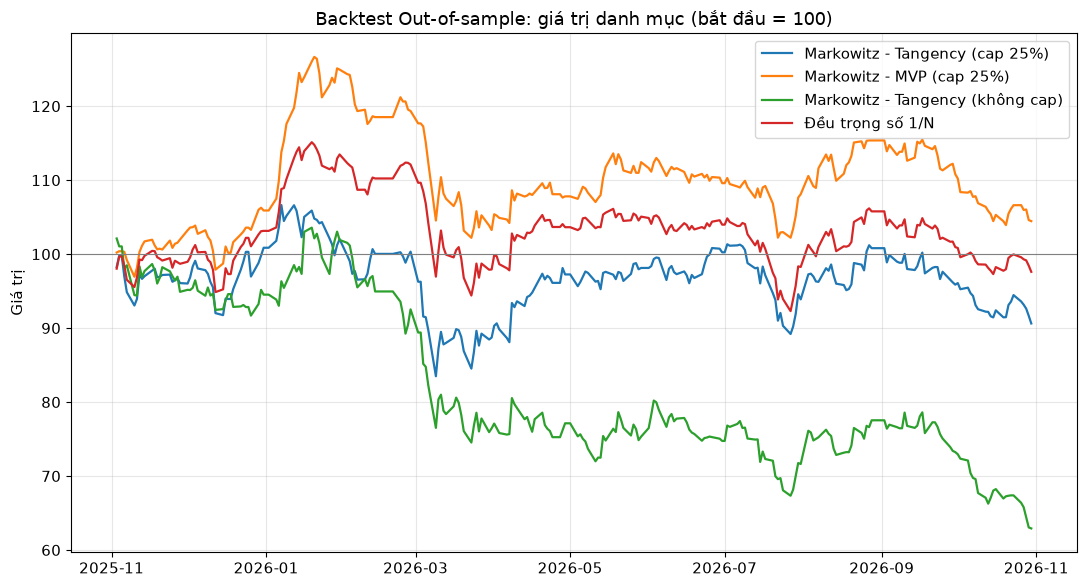

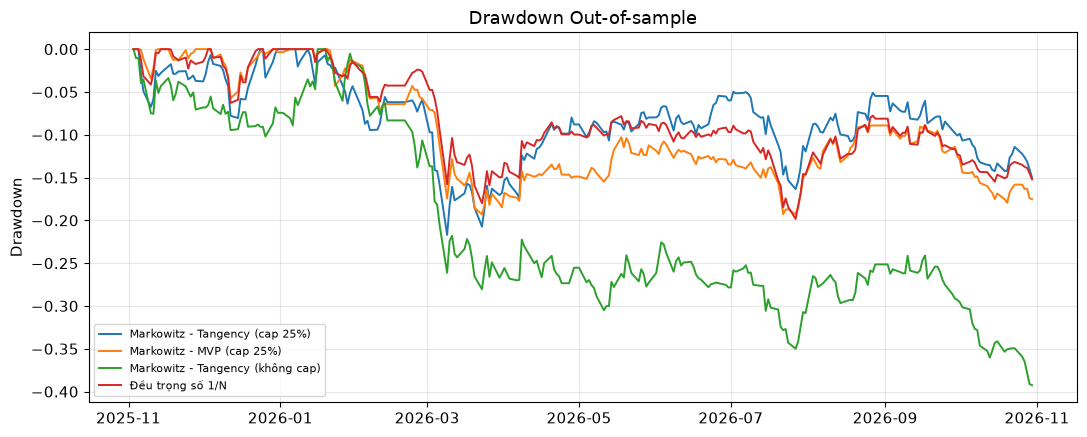

In [17]:
# %% ===== CHƯƠNG 3: RÀNG BUỘC THỰC TẾ & KIỂM THỬ OUT-OF-SAMPLE =====
# ---------- 3.1 Thêm ràng buộc w_i <= 25% ----------
w_mvp_c = optimize_mvp(mu, cov, max_w=MAX_WEIGHT)
w_tan_c = optimize_tangency(mu, cov, max_w=MAX_WEIGHT)
w_eq = np.ones(N) / N

weights3 = pd.DataFrame({"MVP (cap 25%)": w_mvp_c, "Tangency (cap 25%)": w_tan_c, "1/N": w_eq}, index=TICKERS)
print(f"\n=== TỶ TRỌNG KHI CÓ RÀNG BUỘC w_i <= {MAX_WEIGHT:.0%} ===")
print((weights3 * 100).round(2).to_string())
assert (w_tan_c <= MAX_WEIGHT + 1e-6).all() and (w_mvp_c <= MAX_WEIGHT + 1e-6).all()

ax = (weights3 * 100).plot(kind="bar", figsize=(11, 5), width=0.8)
ax.axhline(MAX_WEIGHT * 100, color="red", ls="--", label="Trần 25%")
ax.set_ylabel("Tỷ trọng (%)"); ax.set_title("Tỷ trọng sau khi thêm ràng buộc w_i ≤ 25%")
ax.legend(); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "05_ty_trong_co_rang_buoc.png"), dpi=150)
plt.show()

# ---------- 3.2 Hàm đo lường hiệu quả ----------
def performance(daily_simple_ret, rf=RF):
    """Các chỉ số hiệu quả từ chuỗi lợi nhuận đơn giản theo ngày."""
    r = daily_simple_ret.dropna()
    wealth = (1 + r).cumprod()
    ann_ret = (1 + r).prod() ** (TRADING_DAYS / len(r)) - 1       # lợi nhuận hình học/năm
    ann_vol = r.std() * np.sqrt(TRADING_DAYS)
    dd = wealth / wealth.cummax() - 1
    return {"Lợi nhuận tích lũy": wealth.iloc[-1] - 1,
            "Lợi nhuận/năm": ann_ret,
            "Độ biến động/năm": ann_vol,
            "Sharpe": (ann_ret - rf) / ann_vol,
            "Max Drawdown": dd.min()}


def portfolio_daily_returns(w, log_returns):
    """Lợi nhuận đơn giản hằng ngày của danh mục giữ tỷ trọng cố định."""
    simple = np.exp(log_returns) - 1
    return pd.Series(simple.values @ w, index=log_returns.index)


# ---------- 3.3 Backtest Out-of-sample (trọng số cố định ước lượng từ In-sample) ----------
strategies = {
    "Markowitz - Tangency (cap 25%)": w_tan_c,
    "Markowitz - MVP (cap 25%)": w_mvp_c,
    "Markowitz - Tangency (không cap)": w_tan,
    "Đều trọng số 1/N": w_eq,
}
oos = {name: portfolio_daily_returns(w, ret_test) for name, w in strategies.items()}

if vnindex is not None and len(vnindex.loc[TEST_START:]) > 10:
    vn_ret = vnindex.pct_change().dropna().loc[TEST_START:]
    oos["VN-Index"] = vn_ret.reindex(ret_test.index).fillna(0)
else:
    print("⚠️  Không có dữ liệu VN-Index → bỏ qua benchmark. "
          "Bạn có thể tự thêm cột 'VNINDEX' vào data/raw_prices.csv.")

tab_oos = pd.DataFrame({k: performance(v) for k, v in oos.items()}).T
print(f"\n=== KẾT QUẢ OUT-OF-SAMPLE ({ret_test.index[0].date()} → {ret_test.index[-1].date()}) ===")
print(tab_oos.round(4).to_string())

# So sánh In-sample vs Out-of-sample (minh họa Estimation Error)
ins = {}
for name, w in strategies.items():
    ins[name] = performance(portfolio_daily_returns(w, ret_train))
cmp = pd.DataFrame({
    "Sharpe In-sample": {k: v["Sharpe"] for k, v in ins.items()},
    "Sharpe Out-of-sample": {k: tab_oos.loc[k, "Sharpe"] for k in strategies},
})
cmp["Chênh lệch"] = cmp["Sharpe Out-of-sample"] - cmp["Sharpe In-sample"]
print("\n=== SAI SỐ ƯỚC LƯỢNG (Estimation Error): Sharpe In-sample vs Out-of-sample ===")
print(cmp.round(4).to_string())

# Biểu đồ giá trị tích lũy
fig, ax = plt.subplots(figsize=(11, 6))
for name, r in oos.items():
    ax.plot((1 + r).cumprod() * 100, label=name, lw=2.5 if name == "VN-Index" else 1.6,
            ls="--" if name == "VN-Index" else "-")
ax.axhline(100, color="gray", lw=0.8)
ax.set_title("Backtest Out-of-sample: giá trị danh mục (bắt đầu = 100)")
ax.set_ylabel("Giá trị"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "06_backtest_oos.png"), dpi=150)
plt.show()

# Biểu đồ Drawdown
fig, ax = plt.subplots(figsize=(11, 4.5))
for name, r in oos.items():
    w_ = (1 + r).cumprod()
    ax.plot(w_ / w_.cummax() - 1, label=name, lw=1.4)
ax.set_title("Drawdown Out-of-sample"); ax.set_ylabel("Drawdown"); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "07_drawdown_oos.png"), dpi=150)
plt.show()


=== ROLLING BACKTEST (từ 2023-10-09) ===
                            Lợi nhuận tích lũy  Lợi nhuận/năm  Độ biến động/năm  Sharpe  Max Drawdown
Rolling Tangency (cap 25%)              0.3329         0.0947            0.2254  0.2873       -0.2566
Rolling MVP (cap 25%)                   0.2137         0.0629            0.1856  0.1772       -0.2754
Đều trọng số 1/N                        0.4175         0.1162            0.1919  0.4491       -0.2082


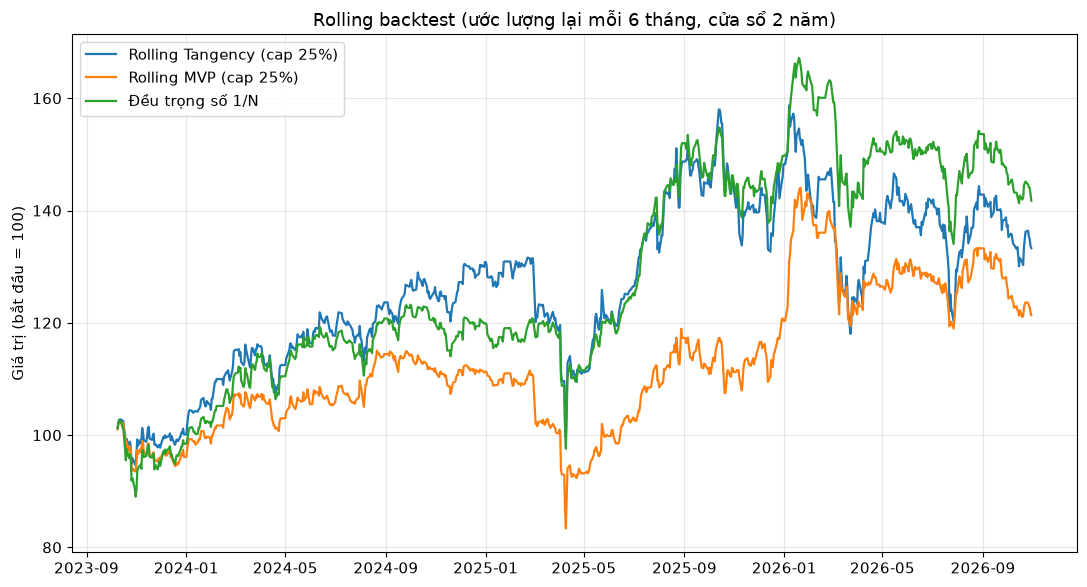

In [18]:
# %% ---------- 3.4 (MỞ RỘNG) Rolling backtest: tái cân bằng định kỳ ----------
# Một kỳ kiểm thử duy nhất dễ bị "may/rủi". Rolling backtest lặp lại quy trình nhiều lần:
# mỗi 6 tháng, ước lượng lại trên 2 năm gần nhất rồi giữ danh mục 6 tháng kế tiếp.
LOOKBACK, REBAL = 504, 126      # ~2 năm, ~6 tháng

def rolling_backtest(log_returns, lookback=LOOKBACK, rebal=REBAL, max_w=MAX_WEIGHT, kind="tangency"):
    pieces = []
    for start in range(lookback, len(log_returns), rebal):
        window = log_returns.iloc[start - lookback:start]
        mu_w, cov_w = annual_stats(window)
        w = optimize_tangency(mu_w, cov_w, max_w=max_w) if kind == "tangency" else optimize_mvp(mu_w, cov_w, max_w)
        nxt = log_returns.iloc[start:start + rebal]
        pieces.append(portfolio_daily_returns(w, nxt))
    return pd.concat(pieces)

if len(log_ret) > LOOKBACK + REBAL:
    roll = {
        "Rolling Tangency (cap 25%)": rolling_backtest(log_ret, kind="tangency"),
        "Rolling MVP (cap 25%)": rolling_backtest(log_ret, kind="mvp"),
    }
    first = next(iter(roll.values())).index[0]
    roll["Đều trọng số 1/N"] = portfolio_daily_returns(w_eq, log_ret.loc[first:])
    if vnindex is not None:
        roll["VN-Index"] = vnindex.pct_change().dropna().reindex(roll["Đều trọng số 1/N"].index).fillna(0)

    tab_roll = pd.DataFrame({k: performance(v) for k, v in roll.items()}).T
    print(f"\n=== ROLLING BACKTEST (từ {first.date()}) ===")
    print(tab_roll.round(4).to_string())

    fig, ax = plt.subplots(figsize=(11, 6))
    for name, r in roll.items():
        ax.plot((1 + r).cumprod() * 100, label=name, lw=1.6)
    ax.set_title("Rolling backtest (ước lượng lại mỗi 6 tháng, cửa sổ 2 năm)")
    ax.set_ylabel("Giá trị (bắt đầu = 100)"); ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "08_rolling_backtest.png"), dpi=150)
    plt.show()
    tab_roll.to_csv(os.path.join(OUT_DIR, "ket_qua_rolling.csv"), encoding="utf-8-sig")

In [19]:
# %% ---------- 3.5 Xuất bảng kết quả & nhận xét tự động ----------
with pd.ExcelWriter(os.path.join(OUT_DIR, "ket_qua_tong_hop.xlsx")) as xw:
    tab2.to_excel(xw, sheet_name="InSample_LongOnly")
    weights2.to_excel(xw, sheet_name="TyTrong_LongOnly")
    weights3.to_excel(xw, sheet_name="TyTrong_Cap25")
    tab_oos.to_excel(xw, sheet_name="OutOfSample")
    cmp.to_excel(xw, sheet_name="EstimationError")

best = tab_oos["Sharpe"].idxmax()
mk = "Markowitz - Tangency (cap 25%)"
print("\n" + "=" * 70)
print("NHẬN XÉT NHANH (tự động - hãy diễn giải lại bằng lời trong báo cáo)")
print("=" * 70)
print(f"• Chiến lược có Sharpe Out-of-sample cao nhất: {best} ({tab_oos.loc[best, 'Sharpe']:.2f})")
print(f"• Markowitz Tangency (cap 25%): Sharpe {tab_oos.loc[mk, 'Sharpe']:.2f} vs 1/N {tab_oos.loc['Đều trọng số 1/N', 'Sharpe']:.2f}")
print(f"• Sharpe của Tangency (cap 25%) thay đổi từ {cmp.loc[mk, 'Sharpe In-sample']:.2f} (In-sample) "
      f"sang {cmp.loc[mk, 'Sharpe Out-of-sample']:.2f} (Out-of-sample) → chênh lệch này phản ánh Estimation Error.")
print("• Gợi ý phân tích: Markowitz rất nhạy với lợi nhuận kỳ vọng ước lượng; ràng buộc cap 25% giúp giảm tập trung;")
print("  danh mục 1/N đơn giản nhưng thường 'khó bị đánh bại' khi ngoài mẫu (DeMiguel et al., 2009).")
print(f"\nĐã lưu biểu đồ & bảng vào thư mục '{OUT_DIR}/' và dữ liệu vào '{DATA_DIR}/'.")


NHẬN XÉT NHANH (tự động - hãy diễn giải lại bằng lời trong báo cáo)
• Chiến lược có Sharpe Out-of-sample cao nhất: Markowitz - MVP (cap 25%) (0.07)
• Markowitz Tangency (cap 25%): Sharpe -0.52 vs 1/N -0.27
• Sharpe của Tangency (cap 25%) thay đổi từ 0.49 (In-sample) sang -0.52 (Out-of-sample) → chênh lệch này phản ánh Estimation Error.
• Gợi ý phân tích: Markowitz rất nhạy với lợi nhuận kỳ vọng ước lượng; ràng buộc cap 25% giúp giảm tập trung;
  danh mục 1/N đơn giản nhưng thường 'khó bị đánh bại' khi ngoài mẫu (DeMiguel et al., 2009).

Đã lưu biểu đồ & bảng vào thư mục 'outputs/' và dữ liệu vào 'data/'.
